In [15]:
#!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import auc, roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [17]:
df = pd.read_csv("course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [18]:
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [19]:
categorical = ["lead_source", 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']

na_values = {"lead_score": 0.0, "annual_income": 0.0, "lead_source": "NA", 
             "industry": "NA", "employment_status": "NA", "location": "NA"}

df = df.fillna(value=na_values)

In [20]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

### Question 1: ROC AUC feature importance

In [21]:
for num in numerical:
    auc = roc_auc_score(df_train['converted'], df_train[num])
    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -df_train[num])
    print(f"col: {num}, auc: {auc}")

col: annual_income, auc: 0.6081977776250831
col: number_of_courses_viewed, auc: 0.7229894623989618
col: interaction_count, auc: 0.7649203047563227
col: lead_score, auc: 0.7882254810906102
col: converted, auc: 1.0


### Question 2: Training the model

In [22]:
numerical_X = ["annual_income", "number_of_courses_viewed", "interaction_count",
            "lead_score"]

features = categorical + numerical_X

train_dict = df_train[features].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)

X_val  = dv.transform(df_val[features].to_dict(orient='records'))
X_test = dv.transform(df_test[features].to_dict(orient='records'))

y_train = df_train['converted'].astype(int).values
y_val   = df_val['converted'].astype(int).values
y_test  = df_test['converted'].astype(int).values

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [23]:
y_pred = model.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7318222288173319

### Question 3: Precision and Recall

In [24]:
scores = []

thresholds = np.arange(0.0, 1.0, 0.01)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

df_scores['p_r_diff'] = abs(df_scores['precision']-df_scores['recall'])

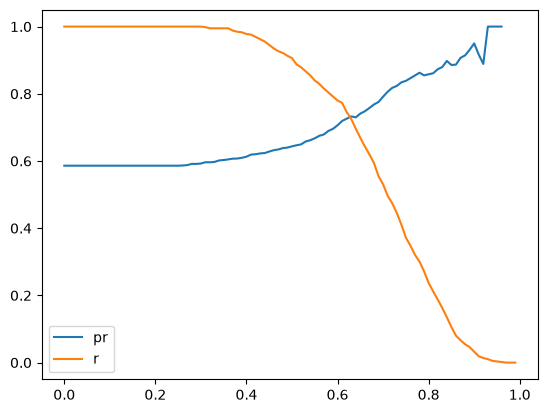

In [25]:
plt.plot(df_scores.threshold, df_scores['precision'], label='pr')
plt.plot(df_scores.threshold, df_scores['recall'], label='r')
plt.legend()

### Question 4: F1 score

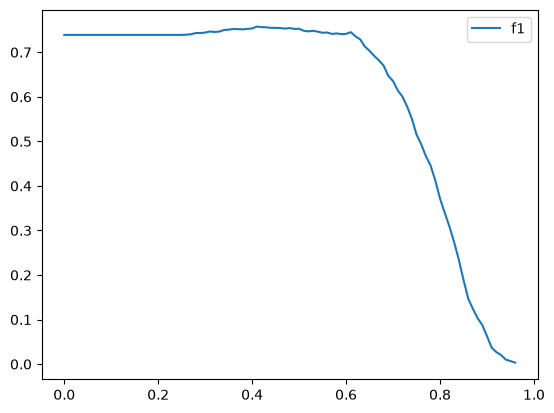

In [26]:
df_scores['f1'] = 2 * (df_scores['precision'] * df_scores['recall']) / (df_scores['precision'] + df_scores['recall'])
plt.plot(df_scores.threshold, df_scores['f1'], label='f1')
plt.legend()

### Question 5: 5-Fold CV

In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

aucs = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    X_train = dv.transform(df_train[features].to_dict(orient='records'))
    X_val = dv.transform(df_val[features].to_dict(orient='records'))

    y_train = df_train['converted'].astype(int).values
    y_val = df_val['converted'].astype(int).values

    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    aucs.append(roc_auc_score(y_val, y_pred))

round(np.std(aucs), 3)

np.float64(0.007)

### Question 6:  Hyperparameter Tuning

In [ ]:
Cs = [0.000001, 0.001, 1]

aucs = [[], [], []]

for train_idx, val_idx in kfold.split(df_full_train):
    for i in range(3):
        model = LogisticRegression(solver='liblinear', C=Cs[i], max_iter=1000)

        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        X_train = dv.transform(df_train[features].to_dict(orient='records'))
        X_val = dv.transform(df_val[features].to_dict(orient='records'))

        y_train = df_train['converted'].astype(int).values
        y_val = df_val['converted'].astype(int).values

        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        aucs[i].append(roc_auc_score(y_val, y_pred))


for i in range(3):
    print(f'C: {Cs[i]}, std: {round(np.std(aucs[i]), 3)}, mean: {round(np.mean(aucs[i]), 3)}')


C: 1e-06, std: 0.019, mean: 0.617
C: 0.001, std: 0.01, mean: 0.749
C: 1, std: 0.007, mean: 0.732
